In [10]:
import pandas as pd
import matplotlib.pyplot as plt

In [70]:
import os
import pandas as pd
import yaml

base_dir = "/home/vahid/Projects/pythonProject/PoC/experiments/gnn_run/edge_level/normal/EllipticPP"
experiment_records = []
for root, dirs, files in os.walk(base_dir):
    if "hparams.yaml" in files and "metrics.csv" in files:
        hparams_path = os.path.join(root, "hparams.yaml")
        metrics_path = os.path.join(root, "metrics.csv")
        experiment_name = os.path.basename(os.path.dirname(root))  # e.g., the timestamp directory
        with open(hparams_path, "r") as f:
            hparams = yaml.safe_load(f)

        metrics_df = pd.read_csv(metrics_path)

        last_metrics = metrics_df.iloc[-1].to_dict()
        record = {
            "experiment": experiment_name,
            **hparams,
            **last_metrics,
        }

        experiment_records.append(record)

df = pd.DataFrame(experiment_records)
df = df.dropna(subset=['test_avg_pr'])
df.drop(['train_au_roc', 'train_aucnpr', 'step',
       'train_avg_pr', 'train_loss', 'val_au_roc', 'val_aucnpr', 'val_avg_pr',
       'val_loss'],axis=1,inplace=True)
df

,experiment,dataset_name,drop_ratio,dropout,epochs,gnn_type,hidden_size,learning_rate,num_layers,use_graph_features,epoch,gpu_memory_allocated_MB,gpu_memory_reserved_MB,test_au_roc,test_aucnpr,test_avg_pr,test_loss,time_sec
0,2025-07-07_19:31:24,EllipticPP,0.5,0.0,1000,GCN,32,0.005,2,True,1000.0,551.389160,1612.709839,0.988637,0.556892,0.557514,0.020936,0.015712
1,2025-07-07_17:54:33,EllipticPP,0.5,0.2,1000,GCN,32,0.005,1,False,1000.0,452.717560,1419.771851,0.987759,0.573868,0.574466,0.010398,0.015431
2,2025-07-07_18:37:57,EllipticPP,0.5,0.2,1000,GCN,64,0.005,1,False,1000.0,533.139465,2124.415039,0.985836,0.667560,0.668027,0.009991,0.018873
3,2025-07-07_20:58:00,EllipticPP,0.5,0.0,1000,GCN,128,0.005,2,True,1000.0,794.908691,3711.958984,0.952800,0.135640,0.136853,0.040832,0.025758
4,2025-07-07_19:20:33,EllipticPP,0.5,0.2,1000,GCN,128,0.005,1,False,1000.0,696.114197,3519.020752,0.983612,0.409258,0.410087,0.015268,0.020995
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70,2025-07-08_00:48:22,EllipticPP,0.5,0.0,1000,GAT,64,0.005,2,False,1000.0,533.173218,2118.123535,0.989023,0.652262,0.652750,0.010411,0.017329
71,2025-07-07_23:30:37,EllipticPP,0.5,0.2,1000,GAT,128,0.005,1,True,1000.0,794.776550,3716.153320,0.987945,0.624650,0.625177,0.013518,0.022033
72,2025-07-08_00:58:26,EllipticPP,0.5,0.2,1000,GAT,64,0.005,2,True,1000.0,631.835632,2319.450195,0.950508,0.280621,0.281630,0.025042,0.021976
73,2025-07-07_23:19:50,EllipticPP,0.5,0.0,1000,GAT,128,0.005,1,False,1000.0,696.114197,3514.826904,0.981238,0.679360,0.679810,0.009613,0.018206


In [71]:
performance_metrics = ['test_au_roc', 'test_aucnpr', 'test_avg_pr', 'test_loss']
grouped = df.groupby(['use_graph_features','gnn_type'])[performance_metrics].mean().reset_index()
grouped

,use_graph_features,gnn_type,test_au_roc,test_aucnpr,test_avg_pr,test_loss
0,False,GAT,0.978007,0.501090,0.501790,0.015757
1,False,GCN,0.975493,0.514571,0.515252,0.016648
2,False,GIN,0.952265,0.408675,0.409505,0.030376
3,True,GAT,0.964935,0.413238,0.414061,0.023249
4,True,GCN,0.949095,0.303755,0.304732,0.032358
5,True,GIN,0.969831,0.487940,0.488659,0.018965


In [21]:
import pandas as pd

# Sample structure for demonstration (replace with actual df if provided)
# Assuming df is already loaded

# Example column names based on user's description
# group_cols = ['dataset_name', 'drop_ratio', 'dropout', 'epochs',
#               'gnn_type', 'hidden_size', 'learning_rate', 'num_layers']
performance_metrics = ['test_au_roc', 'test_aucnpr', 'test_avg_pr', 'test_loss']

# Placeholder: generate example DataFrame if needed
# df = pd.read_csv("your_file.csv")  # replace this line with actual loading if needed

# Group by all config columns + use_graph_features to get performance
grouped = df.groupby(['use_graph_features'])[performance_metrics].mean().reset_index()

# Pivot so that use_graph_features becomes columns (False and True)
pivoted = grouped.pivot(index=group_cols, columns='use_graph_features', values=performance_metrics)

# Flatten column MultiIndex
pivoted.columns = [f"{metric}_{'with_graph' if use_graph else 'no_graph'}" for metric, use_graph in pivoted.columns]
pivoted = pivoted.reset_index()
pivoted

,dataset_name,drop_ratio,dropout,epochs,gnn_type,hidden_size,learning_rate,num_layers,test_au_roc_no_graph,test_au_roc_with_graph,test_aucnpr_no_graph,test_aucnpr_with_graph,test_avg_pr_no_graph,test_avg_pr_with_graph,test_loss_no_graph,test_loss_with_graph
0,PaySim,0.9,0.0,1000,GAT,32,0.005,1,0.817341,0.837867,0.537302,0.577112,0.539542,0.579160,8.660681,8.847404
1,PaySim,0.9,0.0,1000,GAT,32,0.005,2,0.852521,0.887037,0.592218,0.655080,0.594191,0.656750,10.496770,9.414028
2,PaySim,0.9,0.0,1000,GAT,64,0.005,1,0.865713,0.828877,0.678643,0.559213,0.680199,0.561347,11.605976,8.863414
3,PaySim,0.9,0.0,1000,GAT,64,0.005,2,0.831452,0.979323,0.566677,0.838739,0.568774,0.839519,8.573293,2.248750
4,PaySim,0.9,0.0,1000,GAT,128,0.005,1,0.874316,0.875864,0.603969,0.593246,0.605887,0.595215,27.116901,10.070847
5,PaySim,0.9,0.0,1000,GAT,128,0.005,2,0.864974,0.893503,0.574189,0.595563,0.576250,0.597520,8.383702,6.461135
6,PaySim,0.9,0.0,1000,GCN,32,0.005,1,0.865595,0.881598,0.659847,0.608604,0.661493,0.610498,3.977915,9.959909
7,PaySim,0.9,0.0,1000,GCN,32,0.005,2,0.926727,0.893414,0.375618,0.659609,0.378640,0.661257,8.201434,7.177241
8,PaySim,0.9,0.0,1000,GCN,64,0.005,1,0.865677,0.846819,0.676008,0.591361,0.677577,0.593339,3.095336,8.199221
9,PaySim,0.9,0.0,1000,GCN,64,0.005,2,0.856717,0.824650,0.656266,0.590787,0.657930,0.592768,6.778059,7.307279


## Sliding performance

In [32]:
def load_metrics(base_path, first_rows_drop=0):
    """Load test performance metrics from all timestamp directories."""
    data = []
    counter = 0
    for dir_name in sorted(os.listdir(base_path), key=lambda x: int(x.split("_")[-1])):  # Sort by index
        dir_path = os.path.join(base_path, dir_name)
        file_path = os.path.join(f"{dir_path}/lightning_logs", "metrics.csv")
        print(file_path)
        if os.path.exists(file_path):
            df = pd.read_csv(file_path)
            # df.columns = ["epoch", "gpu_memory_allocated_MB", "gpu_memory_reserved_MB", "step",
            #               "test_au_roc", "test_avg_pr", "test_loss", "time_sec",
            #               "train_au_roc", "train_avg_pr", "train_loss",
            #               "val_au_roc", "val_avg_pr", "val_loss"]

            # Get last epoch's test metrics
            latest_metrics = df.iloc[-1]
            if counter>=first_rows_drop:
                data.append({
                    "timestamp": int(dir_name.split("_")[-1]),
                    "test_au_roc": float(latest_metrics["test_au_roc"]),
                    "test_avg_pr": float(latest_metrics["test_avg_pr"]),
                    "test_loss": float(latest_metrics["test_loss"]),
                    "test_aucnpr": float(latest_metrics["test_aucnpr"]),
                    "gpu_memory_allocated_MB": float(latest_metrics["gpu_memory_allocated_MB"]),
                    "gpu_memory_reserved_MB": float(latest_metrics["gpu_memory_reserved_MB"])
                })
            counter+=1
    return pd.DataFrame(data).sort_values("timestamp")


In [33]:
def avg_metric(df_metrics):
    num_sample = len(df_metrics)
    avg_aucpr = df_metrics['test_avg_pr'].mean()
    avg_aucnpr = df_metrics['test_aucnpr'].mean()
    avg_au_roc = df_metrics['test_au_roc'].mean()
    avg_allocated_MB = df_metrics['gpu_memory_allocated_MB'].mean()
    gpu_memory_reserved_MB = df_metrics['gpu_memory_reserved_MB'].mean()
    return {
        'snapshots': num_sample,
        'avg_aucpr': avg_aucpr,
        'avg_au_roc': avg_au_roc,
        'avg_aucnpr': avg_aucnpr,
        'avg_allocated_MB': avg_allocated_MB,
        'gpu_memory_reserved_MB': gpu_memory_reserved_MB
    }

In [34]:
def load_epoch_metrics(base_path):
    """Load all training and validation metrics for each index directory over epochs."""
    metrics = []

    for dir_name in sorted(os.listdir(base_path), key=lambda x: int(x.split("_")[-1])):  # Sort directories by index
        dir_path = os.path.join(base_path, dir_name)
        file_path = os.path.join(f"{dir_path}/lightning_logs", "metrics.csv")

        if os.path.exists(file_path):
            df = pd.read_csv(file_path, header=None).iloc[1:].reset_index(drop=True)
            df.columns = ["epoch", "gpu_memory_allocated_MB", "gpu_memory_reserved_MB", "step",
                          "test_au_roc", "test_avg_pr","test_aucnpr" "test_loss", "time_sec",
                          "train_au_roc", "train_avg_pr", "train_aucnpr", "train_loss",
                          "val_au_roc", "val_avg_pr", "val_aucnpr", "val_loss"]
            df = df[["epoch", "train_loss", "val_loss", "train_au_roc", "val_au_roc"]]
            train_df = df[["epoch", "train_loss", "train_au_roc"]].dropna()
            val_df = df[["epoch", "val_loss", "val_au_roc"]].dropna()
            merged_df = pd.merge(val_df, train_df, on="epoch", how='inner')
            merged_df["index"] = int(dir_name.split("_")[-1])  # Add index number
            merged_df['epoch'] = merged_df['epoch'].astype(int)
            merged_df[['train_loss', 'val_loss', 'train_au_roc', 'val_au_roc']] = merged_df[['train_loss', 'val_loss', 'train_au_roc', 'val_au_roc']].astype(float)
            metrics.append(merged_df[["index", "epoch", "train_loss", "val_loss", "train_au_roc", "val_au_roc"]])

    return pd.concat(metrics)

In [35]:
def result_preview(result_paths, visualization=False):

    # result_dict = {name.replace("_path",""):load_metrics(path).sort_values("timestamp") for name,path in result_paths.items()}
    result_dict = {load_hparams(path):load_metrics(path).sort_values("timestamp") for path in result_paths}
    if visualization:
        for metric in ["test_au_roc", "test_avg_pr","test_aucnpr", "test_loss"]:
            plt.figure(figsize=(40, 15))
            for result_name, result_df in result_dict.items():
                plt.plot(result_df["timestamp"], result_df[metric],
                 label=result_name)
            plt.xlabel("Timestamp")
            plt.ylabel(metric)
            plt.title(f"Comparison of {metric} over time")
            plt.legend()
            plt.grid()
            plt.show()
    rows = []
    for result_name, result_df in result_dict.items():
        row = avg_metric(result_df)
        row['name'] = result_name
        rows.append(row)

    summary_df = pd.DataFrame(rows)
    summary_df = summary_df.set_index('name')
    return summary_df

In [36]:
def find_dirs_with_exact_indices(base_path,num_indexes,started_index=0):
    expected_dirs = {f"{i}" for i in range(started_index,num_indexes+started_index)}  # from index_0 to num_indexes
    print(expected_dirs)
    matching_dirs = []

    for current_dir, subdirs, files in os.walk(base_path):
        subdirs_set = {item.strip() for item in subdirs}
        if subdirs_set == expected_dirs:
            matching_dirs.append(current_dir)

    return matching_dirs

In [37]:
def load_hparams(dir_path):
    hparam_path = os.path.join(dir_path,"12/lightning_logs/hparams.yaml")
    print(hparam_path)
    if os.path.isfile(hparam_path):
        with open(hparam_path,'r') as f:
            return f"{yaml.safe_load(f)}"
    else:
        return None

{'16', '14', '15', '11', '10', '12', '13', '17', '9'}
10
['/home/vahid/Projects/pythonProject/PoC/experiments/gnn_run/edge_level/sliding/AMLSim/GIN/2025-07-09_16:59:36', '/home/vahid/Projects/pythonProject/PoC/experiments/gnn_run/edge_level/sliding/AMLSim/GIN/2025-07-09_18:30:15', '/home/vahid/Projects/pythonProject/PoC/experiments/gnn_run/edge_level/sliding/AMLSim/GIN/2025-07-09_20:13:03', '/home/vahid/Projects/pythonProject/PoC/experiments/gnn_run/edge_level/sliding/AMLSim/GIN/2025-07-09_19:35:47', '/home/vahid/Projects/pythonProject/PoC/experiments/gnn_run/edge_level/sliding/AMLSim/GIN/2025-07-09_18:02:58', '/home/vahid/Projects/pythonProject/PoC/experiments/gnn_run/edge_level/sliding/AMLSim/GIN/2025-07-09_17:29:38', '/home/vahid/Projects/pythonProject/PoC/experiments/gnn_run/edge_level/sliding/AMLSim/GIN/2025-07-09_21:11:24', '/home/vahid/Projects/pythonProject/PoC/experiments/gnn_run/edge_level/sliding/AMLSim/GIN/2025-07-09_19:06:12', '/home/vahid/Projects/pythonProject/PoC/experi

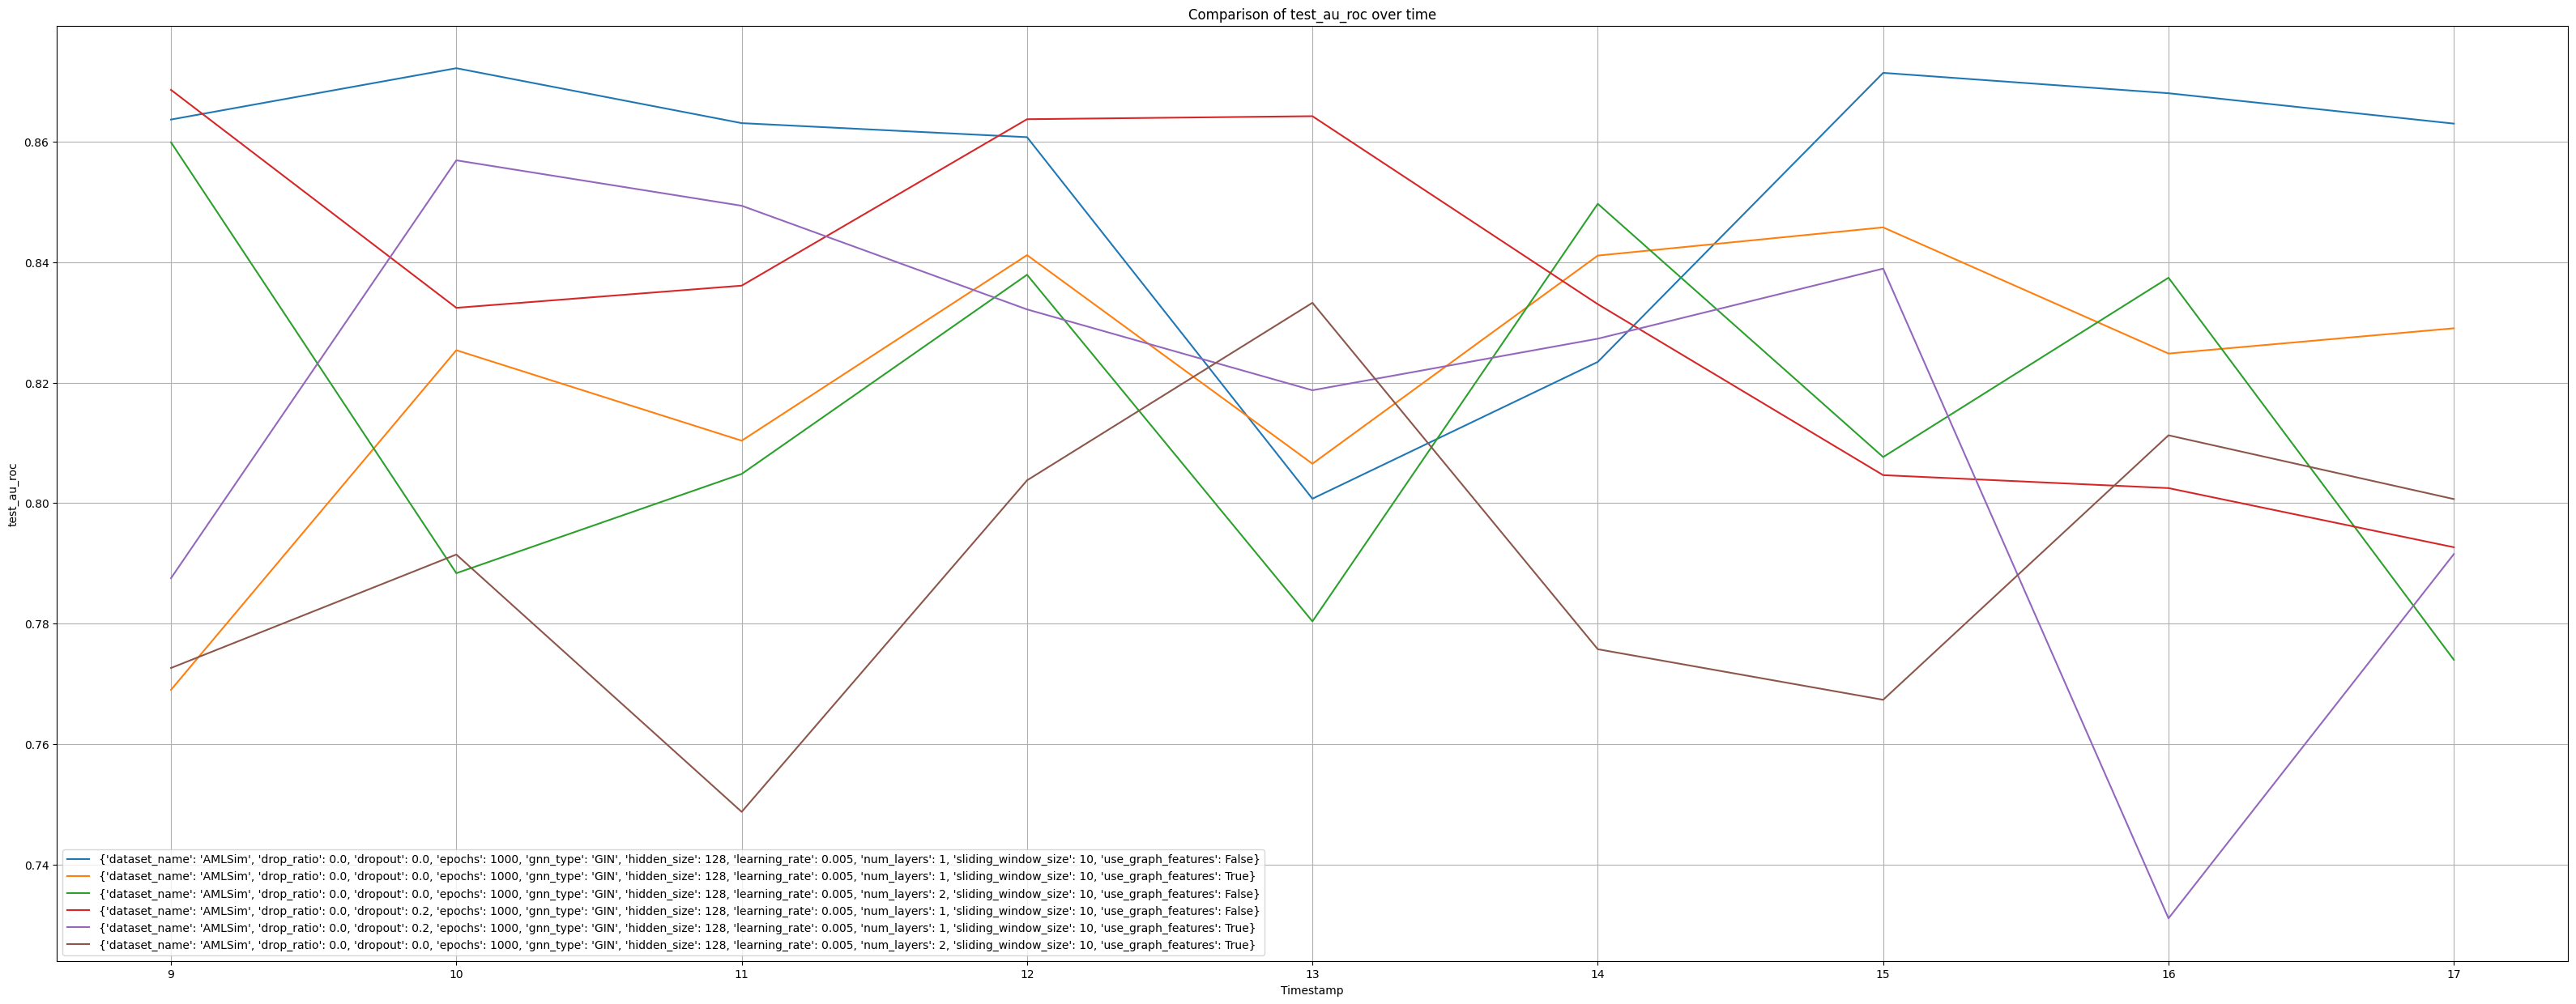

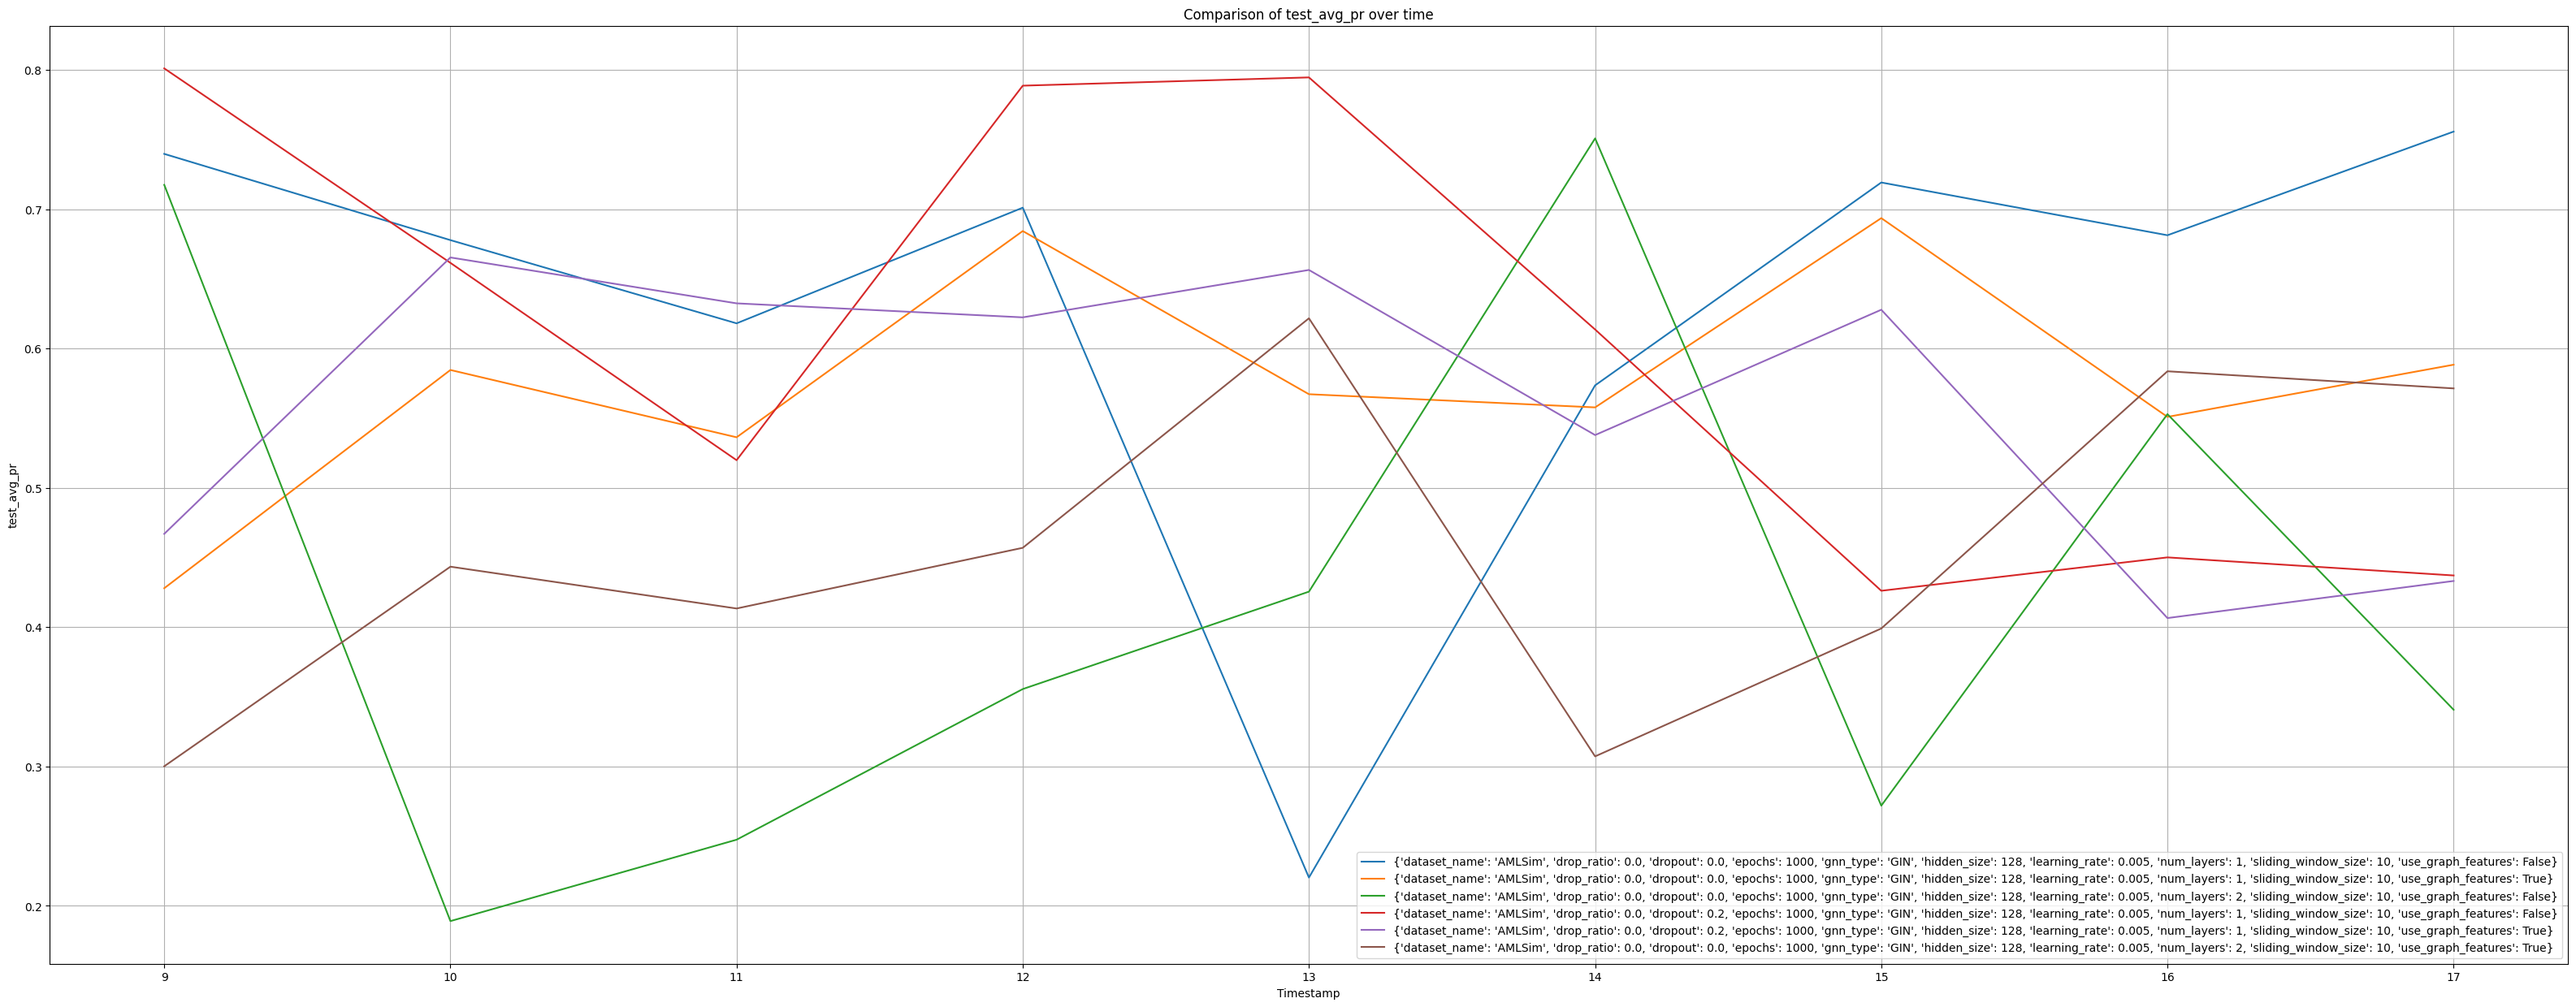

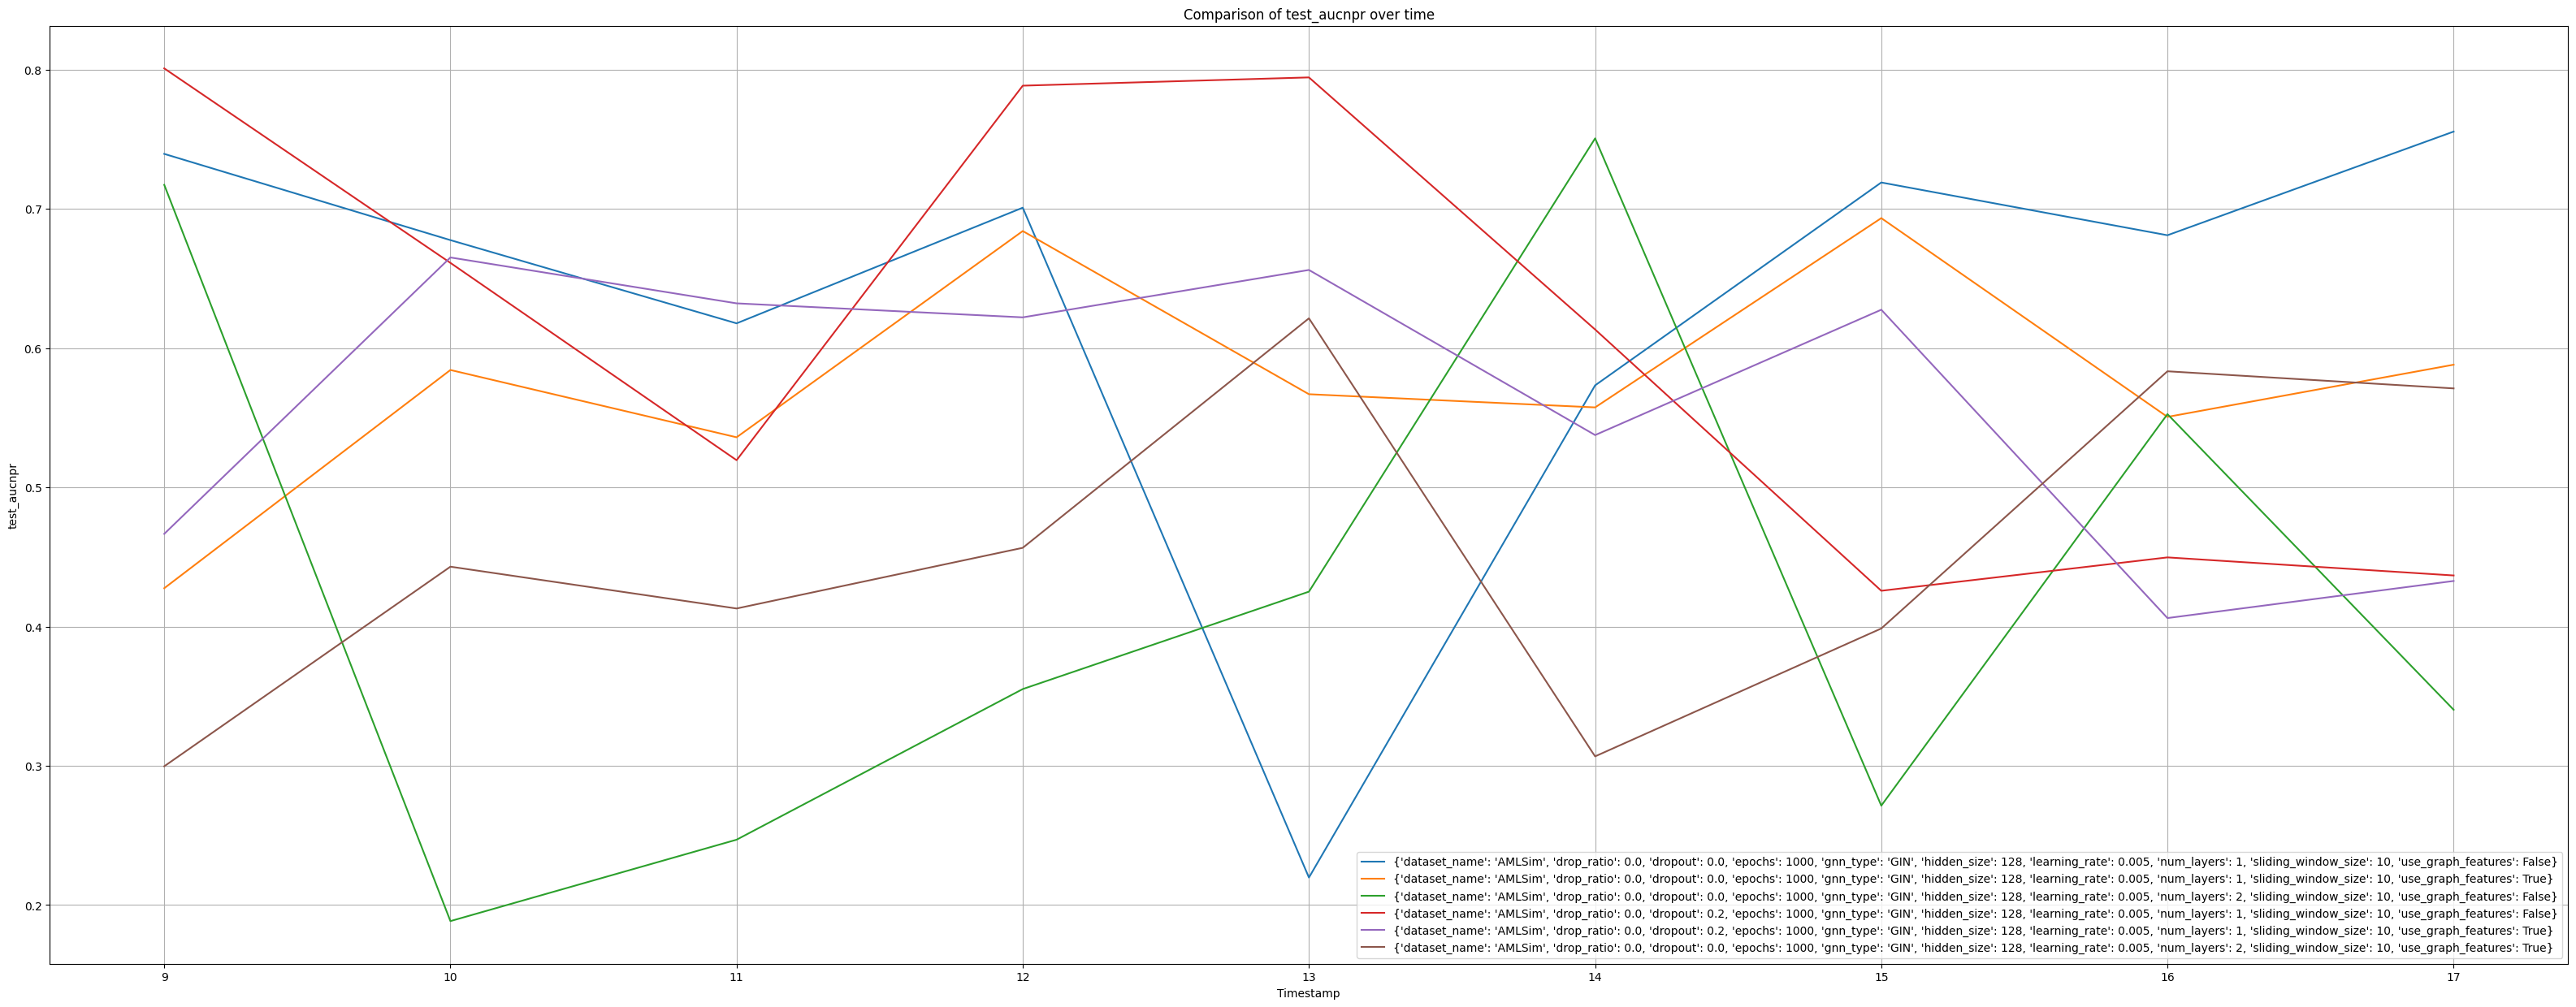

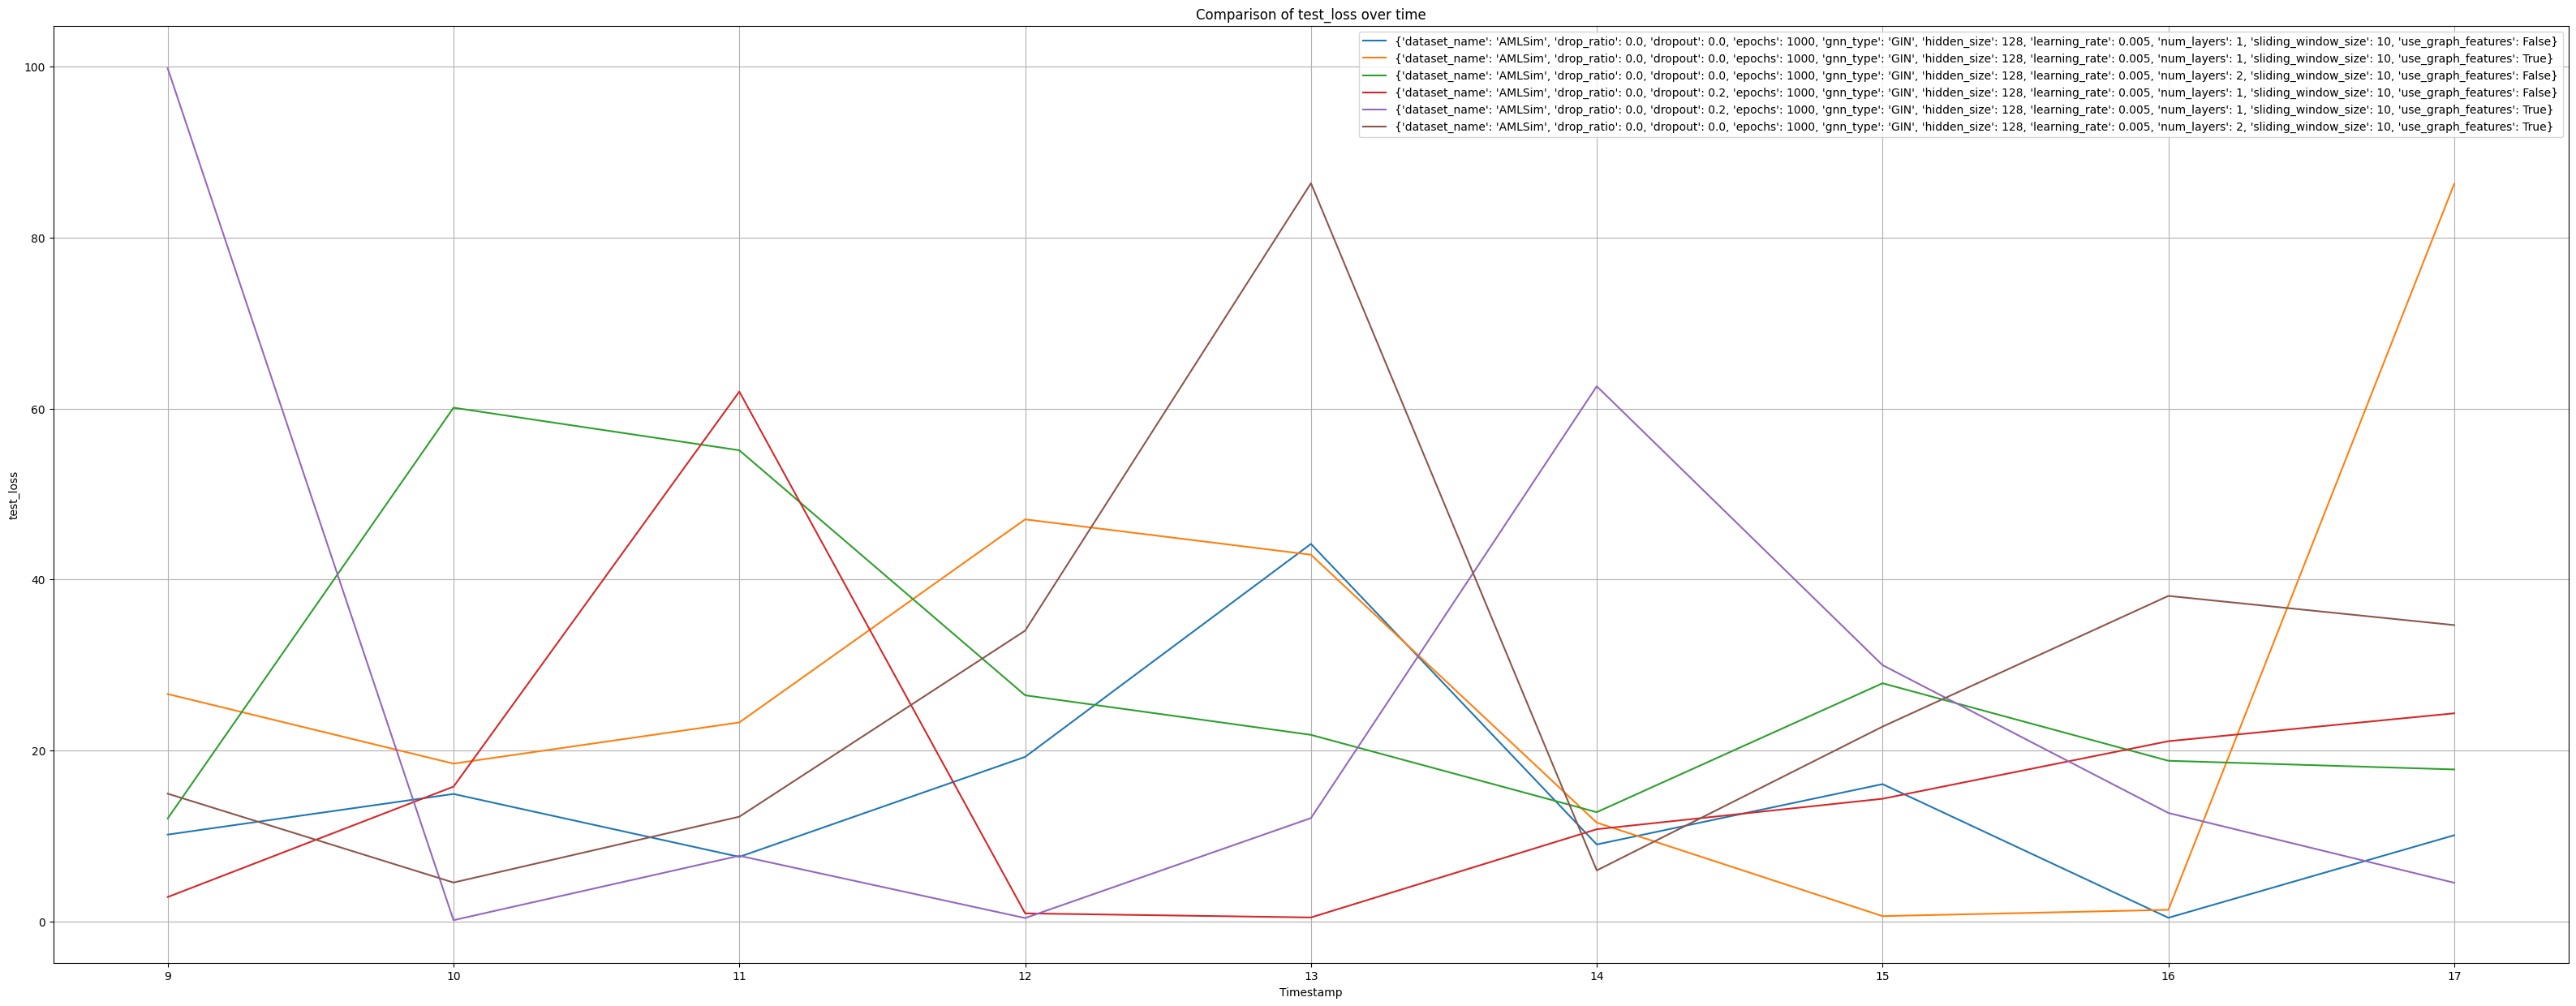

,snapshots,avg_aucpr,avg_au_roc,avg_aucnpr,avg_allocated_MB,gpu_memory_reserved_MB
name,,,,,,
"{'dataset_name': 'AMLSim', 'drop_ratio': 0.0, 'dropout': 0.0, 'epochs': 1000, 'gnn_type': 'GIN', 'hidden_size': 128, 'learning_rate': 0.005, 'num_layers': 1, 'sliding_window_size': 10, 'use_graph_features': False}",9,0.631864,0.854050,0.631606,32.721635,480.247833
"{'dataset_name': 'AMLSim', 'drop_ratio': 0.0, 'dropout': 0.0, 'epochs': 1000, 'gnn_type': 'GIN', 'hidden_size': 128, 'learning_rate': 0.005, 'num_layers': 1, 'sliding_window_size': 10, 'use_graph_features': True}",9,0.576794,0.821464,0.576497,77.545189,557.376383
"{'dataset_name': 'AMLSim', 'drop_ratio': 0.0, 'dropout': 0.0, 'epochs': 1000, 'gnn_type': 'GIN', 'hidden_size': 128, 'learning_rate': 0.005, 'num_layers': 2, 'sliding_window_size': 10, 'use_graph_features': False}",9,0.427955,0.815568,0.427553,32.815899,479.315759
"{'dataset_name': 'AMLSim', 'drop_ratio': 0.0, 'dropout': 0.2, 'epochs': 1000, 'gnn_type': 'GIN', 'hidden_size': 128, 'learning_rate': 0.005, 'num_layers': 1, 'sliding_window_size': 10, 'use_graph_features': False}",9,0.610303,0.833107,0.610029,32.705820,479.781796
"{'dataset_name': 'AMLSim', 'drop_ratio': 0.0, 'dropout': 0.2, 'epochs': 1000, 'gnn_type': 'GIN', 'hidden_size': 128, 'learning_rate': 0.005, 'num_layers': 1, 'sliding_window_size': 10, 'use_graph_features': True}",9,0.561006,0.814833,0.560698,77.537281,557.609395
"{'dataset_name': 'AMLSim', 'drop_ratio': 0.0, 'dropout': 0.0, 'epochs': 1000, 'gnn_type': 'GIN', 'hidden_size': 128, 'learning_rate': 0.005, 'num_layers': 2, 'sliding_window_size': 10, 'use_graph_features': True}",9,0.455238,0.789422,0.454856,77.685193,556.444336


In [39]:
## RedditTitle
base_directory = "/home/vahid/Projects/pythonProject/PoC/experiments/gnn_run/edge_level/sliding/AMLSim"
matching_parents = find_dirs_with_exact_indices(base_directory,9,9)
print(len(matching_parents))
print(matching_parents)
for path in sorted(matching_parents):
    print(path)
    print(load_hparams(path))
x = result_preview(matching_parents,visualization=True)
x